In [1]:
# Pre-trained CNN Models(ImageNet Data)
### VGG16

In [2]:
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import json
import urllib.request

# 1 Load pretrained VGG16
model = models.vgg16(pretrained=True)
model.eval()

# 2 Preprocessing (ImageNet standard)
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 3 Load image
img = Image.open("images/aero.jfif").convert("RGB")
input_tensor = preprocess(img)
input_batch = input_tensor.unsqueeze(0)

# 4 Inference
with torch.no_grad():
    outputs = model(input_batch)
    probabilities = F.softmax(outputs, dim=1)


# 5 Load labels
url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
class_idx = urllib.request.urlopen(url).read().decode("utf-8").splitlines()
print(class_idx)

C:\Users\Asim Shah\anaconda3\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Asim Shah\anaconda3\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich', 'brambling', 'goldfinch', 'house finch', 'junco', 'indigo bunting', 'robin', 'bulbul', 'jay', 'magpie', 'chickadee', 'water ouzel', 'kite', 'bald eagle', 'vulture', 'great grey owl', 'European fire salamander', 'common newt', 'eft', 'spotted salamander', 'axolotl', 'bullfrog', 'tree frog', 'tailed frog', 'loggerhead', 'leatherback turtle', 'mud turtle', 'terrapin', 'box turtle', 'banded gecko', 'common iguana', 'American chameleon', 'whiptail', 'agama', 'frilled lizard', 'alligator lizard', 'Gila monster', 'green lizard', 'African chameleon', 'Komodo dragon', 'African crocodile', 'American alligator', 'triceratops', 'thunder snake', 'ringneck snake', 'hognose snake', 'green snake', 'king snake', 'garter snake', 'water snake', 'vine snake', 'night snake', 'boa constrictor', 'rock python', 'Indian cobra', 'green mamba', 'sea snake', 'horned viper', 'diamondback', 

In [3]:
# 6 Top 3 Predictions
top3_prob, top3_catid = torch.topk(probabilities, 3)
print("Predictions:")

for i in range(top3_prob.size(1)):
    print(f"{class_idx[top3_catid[0][i]]} : {top3_prob[0][i].item():.4f}")

Predictions:
airliner : 0.8779
warplane : 0.0881
projectile : 0.0147


In [4]:
class_idx[0]

'tench'

In [5]:
print(model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [6]:
from torchinfo import summary
summary(model)

Layer (type:depth-idx)                   Param #
VGG                                      --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       1,792
│    └─ReLU: 2-2                         --
│    └─Conv2d: 2-3                       36,928
│    └─ReLU: 2-4                         --
│    └─MaxPool2d: 2-5                    --
│    └─Conv2d: 2-6                       73,856
│    └─ReLU: 2-7                         --
│    └─Conv2d: 2-8                       147,584
│    └─ReLU: 2-9                         --
│    └─MaxPool2d: 2-10                   --
│    └─Conv2d: 2-11                      295,168
│    └─ReLU: 2-12                        --
│    └─Conv2d: 2-13                      590,080
│    └─ReLU: 2-14                        --
│    └─Conv2d: 2-15                      590,080
│    └─ReLU: 2-16                        --
│    └─MaxPool2d: 2-17                   --
│    └─Conv2d: 2-18                      1,180,160
│    └─ReLU: 2-19                

## Transfer learning and Fine-tunning 

In [7]:
# Imports and Device Setup

In [8]:
import torch
import torchvision
import matplotlib.pyplot as plt
import random
import os

from torch import nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from pathlib import Path
from PIL import Image
from timeit import default_timer as timer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

torch.manual_seed(42)
torch.cuda.manual_seed(42)

Using device: cpu


# Data Transforms (VGG19 requires 224×224 + ImageNet normalization)

In [9]:
data_path = Path("fooddata/")
train_dir = data_path / "train"
test_dir = data_path / "test"

In [10]:
train_dir

WindowsPath('fooddata/train')

In [11]:
manual_transforms = transforms.Compose([#
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load Dataset Directly

In [13]:
train_data = datasets.ImageFolder(root=train_dir,
                                   transform=manual_transforms)

test_data = datasets.ImageFolder(root=test_dir,
                                  transform=manual_transforms)

class_names = train_data.classes

train_dataloader = DataLoader(train_data,
                              batch_size=32,
                              shuffle=True)

test_dataloader = DataLoader(test_data,
                             batch_size=32,
                             shuffle=False)

print("Classes:", class_names)

Classes: ['pizza', 'steak', 'sushi']


In [14]:
len(train_data)

225

In [15]:
print("Number of classes:", len(class_names))

Number of classes: 3


In [16]:
print(train_data.classes)
print(train_data.class_to_idx)

['pizza', 'steak', 'sushi']
{'pizza': 0, 'steak': 1, 'sushi': 2}


In [17]:
for i in range(5):
    img, label = train_data[i]
    print(f"Label index: {label} | Class name: {train_data.classes[label]}")

Label index: 0 | Class name: pizza
Label index: 0 | Class name: pizza
Label index: 0 | Class name: pizza
Label index: 0 | Class name: pizza
Label index: 0 | Class name: pizza


In [18]:
# Get class index mapping
from collections import Counter
print(train_data.class_to_idx)
# Count targets
train_targets = train_data.targets
class_counts = Counter(train_targets)
for class_idx, count in class_counts.items():
    print(f"{class_names[class_idx]}: {count}")

{'pizza': 0, 'steak': 1, 'sushi': 2}
pizza: 78
steak: 75
sushi: 72


In [ ]:
plt.figure(figsize=(12,8))

for i in range(9):
    random_idx = random.randint(0, len(train_data)-1)
    img, label = train_data[random_idx]

    plt.subplot(3,3,i+1)
    plt.imshow(img.permute(1,2,0))  # convert CHW → HWC
    plt.title(class_names[label])
    plt.axis(False)

plt.tight_layout()
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0007002..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9131652..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0836544..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0665298..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8267832..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4110641].
Cli

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


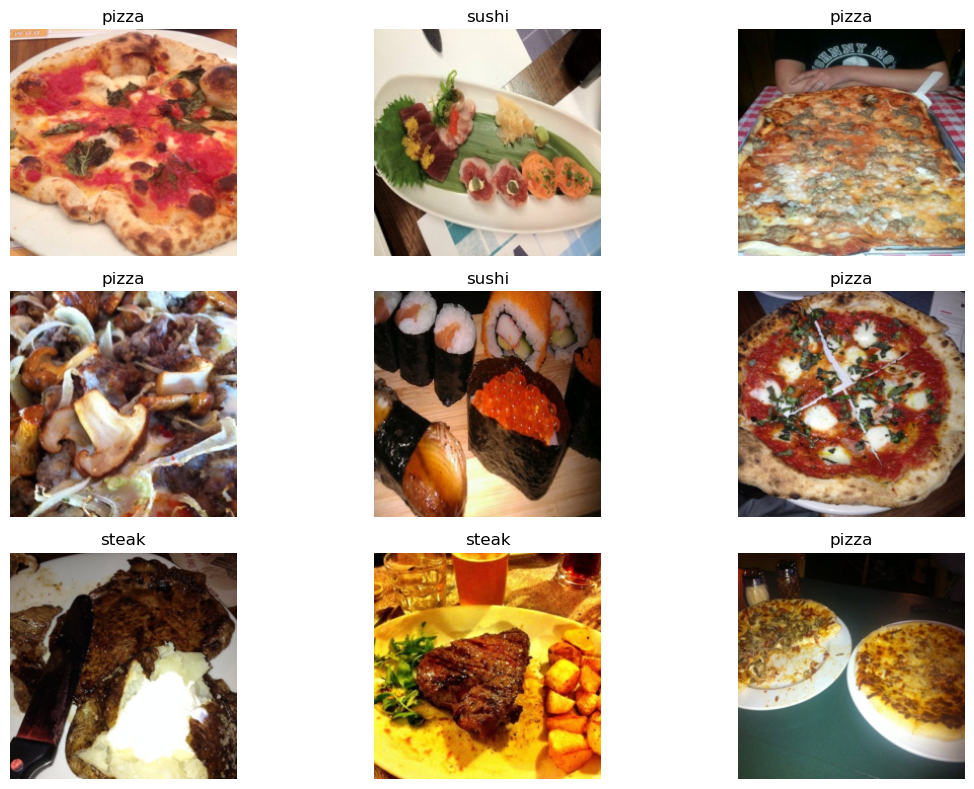

In [13]:
def unnormalize(img):
    img = img.permute(1,2,0).numpy()
    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]
    img = std * img + mean
    return img
plt.figure(figsize=(12,8))
for i in range(9):
    random_idx = random.randint(0, len(train_data)-1)
    img, label = train_data[random_idx]
    plt.subplot(3,3,i+1)
    plt.imshow(unnormalize(img))
    plt.title(class_names[label])
    plt.axis(False)
plt.tight_layout()
plt.show()

In [19]:
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 225
Testing samples: 75


# Loading Pretrained VGG16

In [20]:
weights = torchvision.models.VGG16_Weights.DEFAULT
model = torchvision.models.vgg16(weights=weights)
model = model.to(device)

#weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
#model = torchvision.models.efficientnet_b0(weights=weights)
#model = model.to(device)

In [21]:
from torchinfo import summary
summary(model)

Layer (type:depth-idx)                   Param #
VGG                                      --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       1,792
│    └─ReLU: 2-2                         --
│    └─Conv2d: 2-3                       36,928
│    └─ReLU: 2-4                         --
│    └─MaxPool2d: 2-5                    --
│    └─Conv2d: 2-6                       73,856
│    └─ReLU: 2-7                         --
│    └─Conv2d: 2-8                       147,584
│    └─ReLU: 2-9                         --
│    └─MaxPool2d: 2-10                   --
│    └─Conv2d: 2-11                      295,168
│    └─ReLU: 2-12                        --
│    └─Conv2d: 2-13                      590,080
│    └─ReLU: 2-14                        --
│    └─Conv2d: 2-15                      590,080
│    └─ReLU: 2-16                        --
│    └─MaxPool2d: 2-17                   --
│    └─Conv2d: 2-18                      1,180,160
│    └─ReLU: 2-19                

In [22]:
print(model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [38]:
preprocess = weights.transforms()
preprocess

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

# Freeze Feature Extractor

In [23]:
for param in model.features.parameters():
    param.requires_grad = False

# Replace Classifier Layer

In [25]:
print(model.classifier)

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)


In [26]:

#vgg16
output_shape = len(class_names)

model.classifier[6] = nn.Linear(in_features=4096,
                                out_features=output_shape)

model = model.to(device)
'''
output_shape = len(class_names)

model.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(in_features=1280,
              out_features=output_shape)
)

model = model.to(device)
'''

'\noutput_shape = len(class_names)\n\nmodel.classifier = nn.Sequential(\n    nn.Dropout(p=0.2),\n    nn.Linear(in_features=1280,\n              out_features=output_shape)\n)\n\nmodel = model.to(device)\n'

In [27]:
print(model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [28]:
summary(model)

Layer (type:depth-idx)                   Param #
VGG                                      --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       (1,792)
│    └─ReLU: 2-2                         --
│    └─Conv2d: 2-3                       (36,928)
│    └─ReLU: 2-4                         --
│    └─MaxPool2d: 2-5                    --
│    └─Conv2d: 2-6                       (73,856)
│    └─ReLU: 2-7                         --
│    └─Conv2d: 2-8                       (147,584)
│    └─ReLU: 2-9                         --
│    └─MaxPool2d: 2-10                   --
│    └─Conv2d: 2-11                      (295,168)
│    └─ReLU: 2-12                        --
│    └─Conv2d: 2-13                      (590,080)
│    └─ReLU: 2-14                        --
│    └─Conv2d: 2-15                      (590,080)
│    └─ReLU: 2-16                        --
│    └─MaxPool2d: 2-17                   --
│    └─Conv2d: 2-18                      (1,180,160)
│    └─ReLU: 2-19

# Loss & Optimizer

In [29]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training

In [30]:
def train_step(model, dataloader, loss_fn, optimizer):
    model.train()
    train_loss = 0
    train_acc = 0

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)

        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y)

    return train_loss/len(dataloader), train_acc/len(dataloader)

In [31]:
def test_step(model, dataloader, loss_fn):
    model.eval()
    test_loss = 0
    test_acc = 0

    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            y_pred = model(X)
            loss = loss_fn(y_pred, y)

            test_loss += loss.item()

            y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
            test_acc += (y_pred_class == y).sum().item()/len(y)

    return test_loss/len(dataloader), test_acc/len(dataloader)

In [32]:
epochs = 5

results = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

start_time = timer()

for epoch in range(epochs):
    train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer)
    test_loss, test_acc = test_step(model, test_dataloader, loss_fn)

    print(f"Epoch: {epoch+1}")
    print(f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f}")
    print(f"Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")
    print("-"*30)

    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

Epoch: 1
Train loss: 1.8317 | Train acc: 0.4375
Test loss: 0.5213 | Test acc: 0.7812
------------------------------
Epoch: 2
Train loss: 0.4646 | Train acc: 0.8359
Test loss: 5.9577 | Test acc: 0.4366
------------------------------
Epoch: 3
Train loss: 0.5525 | Train acc: 0.9141
Test loss: 6.7570 | Test acc: 0.4972
------------------------------
Epoch: 4
Train loss: 0.4506 | Train acc: 0.9453
Test loss: 6.5414 | Test acc: 0.5900
------------------------------
Epoch: 5
Train loss: 0.2352 | Train acc: 0.9688
Test loss: 0.8616 | Test acc: 0.8456
------------------------------
Total training time: 776.937 seconds


In [33]:
from sklearn.metrics import classification_report
model.eval()

all_preds = []
all_labels = []

with torch.inference_mode():
    for X, y in test_dataloader:
        X, y = X.to(device), y.to(device)

        y_logits = model(X)
        y_pred = torch.argmax(y_logits, dim=1)

        all_preds.extend(y_pred.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
print(classification_report(all_labels, 
                            all_preds, 
                            target_names=class_names))

              precision    recall  f1-score   support

       pizza       0.79      0.92      0.85        25
       steak       0.88      0.79      0.83        19
       sushi       0.90      0.84      0.87        31

    accuracy                           0.85        75
   macro avg       0.86      0.85      0.85        75
weighted avg       0.86      0.85      0.85        75



In [34]:
torch.save(model.state_dict(), "final_model.pth")

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(results["train_loss"], label="Train Loss")
plt.plot(results["test_loss"], label="Test Loss")
plt.legend()
plt.title("Loss")

plt.subplot(1,2,2)
plt.plot(results["train_acc"], label="Train Acc")
plt.plot(results["test_acc"], label="Test Acc")
plt.legend()
plt.title("Accuracy")

plt.show()

In [35]:
def pred_and_plot_image(model,
                        image_path,
                        class_names,
                        transform,
                        device=device,
                        top_k=3):
    
    # 1 Load image
    img = Image.open(image_path).convert("RGB")
    
    # 2 Prepare model
    model = model.to(device)
    model.eval()
    
    # 3 Transform image
    img_tensor = transform(img).unsqueeze(0).to(device)
    
    # 4 Inference
    with torch.inference_mode():
        logits = model(img_tensor)
        probs = torch.softmax(logits, dim=1)
    
    # 5 Get top-k predictions
    top_probs, top_labels = torch.topk(probs, top_k)
    
    top_probs = top_probs.cpu().numpy().flatten()
    top_labels = top_labels.cpu().numpy().flatten()
    
    # 6 Plot image
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis(False)
    
    title_text = ""
    for i in range(top_k):
        class_name = class_names[top_labels[i]]
        probability = top_probs[i]
        title_text += f"{class_name}: {probability:.3f}\n"
    
    plt.title(title_text.strip())
    plt.show()
    
    # 7 Return prediction info (useful for evaluation)
    return [(class_names[top_labels[i]], float(top_probs[i])) for i in range(top_k)]

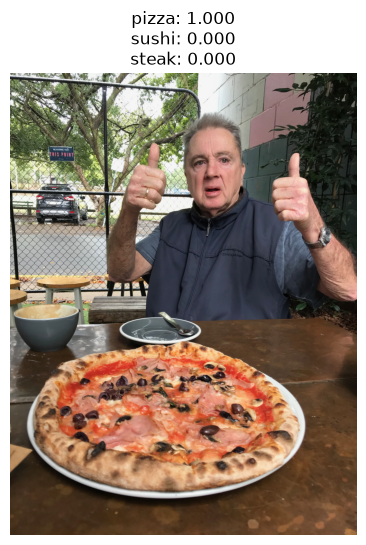

[('pizza', 1.0),
 ('sushi', 1.1281196463097665e-11),
 ('steak', 1.5121692960307076e-12)]

In [37]:
pred_and_plot_image(model=model,
                    image_path="pizza.jpeg",
                    class_names=class_names,
                    transform=manual_transforms,
                    device=device,
                    top_k=3)

# Tasks

Task 1: Feature extraction

Load pretrained VGG16, freeze all CNN layers, replace its final classifier layer for a dataset containing 5 or more classes,can use datasets in pytorch, and train the classifier.

Task 2: Fine-tuning

Modify Task 1 to unfreeze only the final CNN block. Use a smaller learning rate for fine-tuning.

Task 3: Full fine-tuning

Modify the model to train all CNN blocks/two/mix and see the effect on feature maps visually and the new classifier.

Task 4: Compare parameter and results 

Reason/discuss in your words after interpretting different graphs and figures